# EXPLANATORY DATA ANALYSIS

In [1]:
from pathlib import Path
import sys

# Add path to project root
project_root = Path().cwd().parents[0]
sys.path.insert(0, str(project_root))

# Import self made EDA functions
from scripts.explanatory_data_analysis import (
    fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase,
    extract_categorical_columns,
    extract_numerical_columns,
    dataset_structure_and_basic_inspection,
    dataset_quality_inspection,
    descriptive_statistics,
    target_variable_analysis,
    univariate_analysis,
    bevariate_analysis,
    correlation_and_feature_relevance
)

In [2]:

# Dataset path
data_path = project_root / "data" / "raw" / "student_mental_health.csv"

# Store dataframe
df  = fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase(data_path)
# Extract cetegorical columns
categorical_columns = extract_categorical_columns(df)
print(f"Categorical columns: {categorical_columns}")
print("=" * 30)
# Extract numerical columns
numerical_columns = extract_numerical_columns(df)
print(f"Numerical columns: {numerical_columns}")

Categorical columns:      student_id  gender physical_activity part_time_job diet_quality  \
0       STU0001    Male          Moderate            No         Poor   
1       STU0002    Male               Low           Yes      Average   
2       STU0003    Male               Low            No      Average   
3       STU0004    Male              High            No      Average   
4       STU0005  Female          Moderate           Yes          NaN   
...         ...     ...               ...           ...          ...   
1995    STU1996    Male              High            No      Average   
1996    STU1997    Male          Moderate           Yes         Poor   
1997    STU1998  Female               Low           Yes          NaN   
1998    STU1999    Male          Moderate            No         Good   
1999    STU2000  Female              High            No      Average   

     previous_mental_health_history mental_health_risk  
0                                No               High  


In [3]:
# # Dataset structure and basic inspection
# dataset_structure_and_basic_inspection(df)

In [4]:
# # Dataset quality inspection
# dataset_quality_inspection(df)

In [5]:
# # Inspect descriptive statistics
# descriptive_statistics(df)

#### SKEWNESS COMPARISON METRICS
 - -0.5 to 0.5: Fairly symmetrical data.
 - -1.0 to -0.5 or 0.5 to 1.0: Moderate skewness.
 - Less than -1.0 or Greater than 1.0: High/severe skewness.

In [6]:
# # Target variable analysis
# target_variable_analysis(df)

In [7]:
# # Univariate analysis
# univariate_analysis(df)

In [8]:
# # Bevariate analysis
# bevariate_analysis(df)

NUMERICAL FEATURE CORRELATION HEATMAP


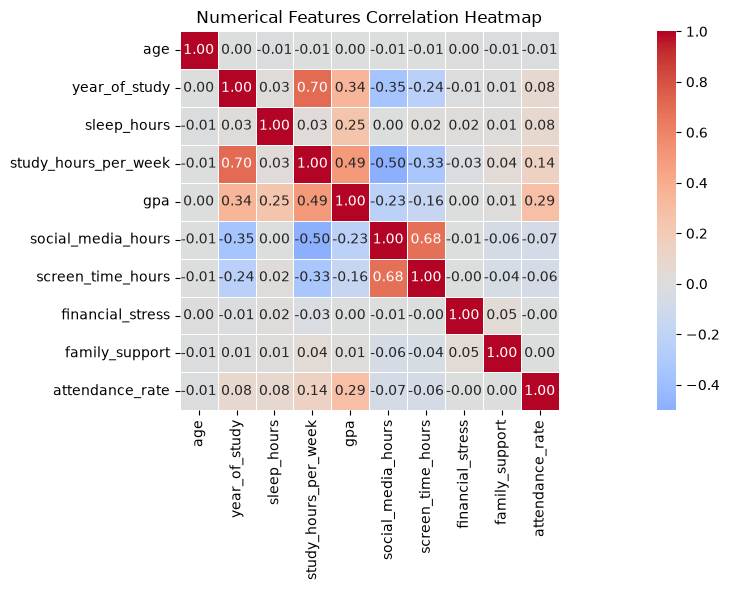

In [9]:
# Correlation and feature relevance
correlation_and_feature_relevance(df)


## Final EDA conclusions

### Data quality
- 2,000 rows, 17 columns (16 features + target `mental_health_risk`).
- Missing values are small, only in 7 columns: Financial_Stress ~4.5%, Diet_Quality ~3.5%, Sleep_Hours ~3.0%, Social_Media_Hours ~3.0%, Family_Support ~2.7%, Attendance_Rate ~2.4%, GPA ~1.9%.
- Duplicates: [fill from your output] rows.
- `student_id` is unique, no missing values.
- Inconsistency found: some rows have `social_media_hours > screen_time_hours`, which is impossible because social media time is part of total screen time. [fill count from your output] rows.
- No impossible values for age, sleep, GPA, or attendance.
- IQR outliers exist mainly in `study_hours_per_week` and `screen_time_hours`, but very high study hours and very low sleep are realistic edge cases, not errors to delete.

### Target and features
- Target is balanced: Low ~660, Medium ~660, High ~680, about 33% each. No class imbalance, so SMOTE is probably not needed.
- No multicollinearity: no pair of numerical features has |corr| > 0.8.
- Strongest numerical features vs target (Low=0, Medium=1, High=2):
  - `sleep_hours` -0.54 — less sleep, higher risk
  - `gpa` -0.35 — lower GPA, higher risk
  - `financial_stress` +0.31 — more stress, higher risk
  - `family_support` -0.25 — less support, higher risk
  - `study_hours_per_week` -0.24, `social_media_hours` +0.21, `screen_time_hours` +0.17
  - `age` 0.005 — no link
- Strongest categorical features vs target (mean risk, 0=Low, 2=High):
  - `previous_mental_health_history`: Yes 1.32 vs No 0.88
  - `physical_activity`: Low 1.23, Moderate 0.98, High 0.71
  - `diet_quality`: Poor 1.18, Average 0.99, Good 0.85
  - `part_time_job`: Yes 1.14 vs No 0.94
  - `gender`: Female 1.01, Male 1.02, Non-binary 0.94 — no real difference

### Recommended preprocessing steps
1. Split first: 80/20 stratified split, `random_state=42`, stratify on `mental_health_risk`.
2. Drop `student_id`, it is only an ID.
3. Imputation, fit on train only: median for numerical columns, mode for categorical columns.
4. Cap `social_media_hours` at `screen_time_hours`.
5. Encoding: ordinal for `physical_activity` (Low/Moderate/High) and `diet_quality` (Poor/Average/Good), one-hot for `gender`, binary for `part_time_job` and `previous_mental_health_history`.
6. Scaling: `StandardScaler` for numerical features, fit on train only, inside a pipeline to avoid leakage.
7. Outliers: keep realistic extremes, cap only clear IQR outliers for `study_hours_per_week` and `screen_time_hours`.
8. No SMOTE, classes are balanced.


In [10]:
display(df.head())
display(df.tail())

,student_id,age,gender,year_of_study,sleep_hours,study_hours_per_week,gpa,social_media_hours,screen_time_hours,physical_activity,financial_stress,family_support,attendance_rate,part_time_job,diet_quality,previous_mental_health_history,mental_health_risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


,student_id,age,gender,year_of_study,sleep_hours,study_hours_per_week,gpa,social_media_hours,screen_time_hours,physical_activity,financial_stress,family_support,attendance_rate,part_time_job,diet_quality,previous_mental_health_history,mental_health_risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium
